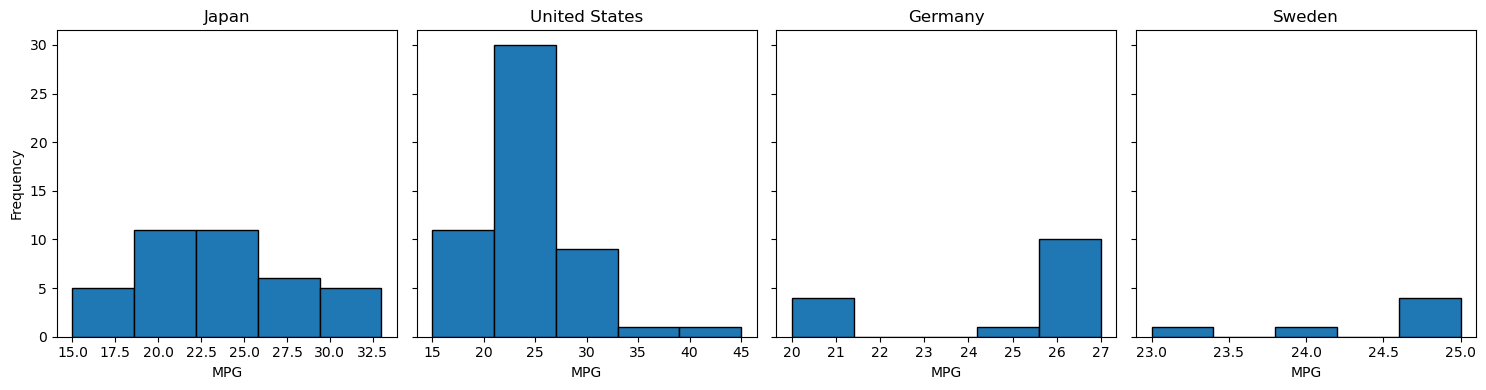

In [11]:
#Question 1

import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('SPSS_cars_v2.csv')
df_clean = df.dropna(subset=['mpg'])

countries = df_clean['country'].unique()
num_countries = len(countries)

fig, axes = plt.subplots(1, num_countries, figsize=(15, 4), sharey=True)
for ax, country in zip(axes, countries):
  country_mpg = df_clean[df_clean['country'] == country]['mpg']
  ax.hist(country_mpg, bins=5, edgecolor='black')
  ax.set_title(country)
  ax.set_xlabel('MPG')

axes[0].set_ylabel('Frequency')
plt.tight_layout()
plt.show()

/var/folders/ch/p9c9jrhx04xdqhx1ng6_bgnh0000gn/T/ipykernel_8907/1834051128.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_by_country, labels=countries)
/var/folders/ch/p9c9jrhx04xdqhx1ng6_bgnh0000gn/T/ipykernel_8907/1834051128.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_by_country, labels=countries)
/var/folders/ch/p9c9jrhx04xdqhx1ng6_bgnh0000gn/T/ipykernel_8907/1834051128.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_by_country, labels=countries)
/var/folders/ch/p9c9jrhx04xdqhx1ng6_bgnh0000gn/T/ipykernel_8907/1834051128.py:11: MatplotlibDeprecation

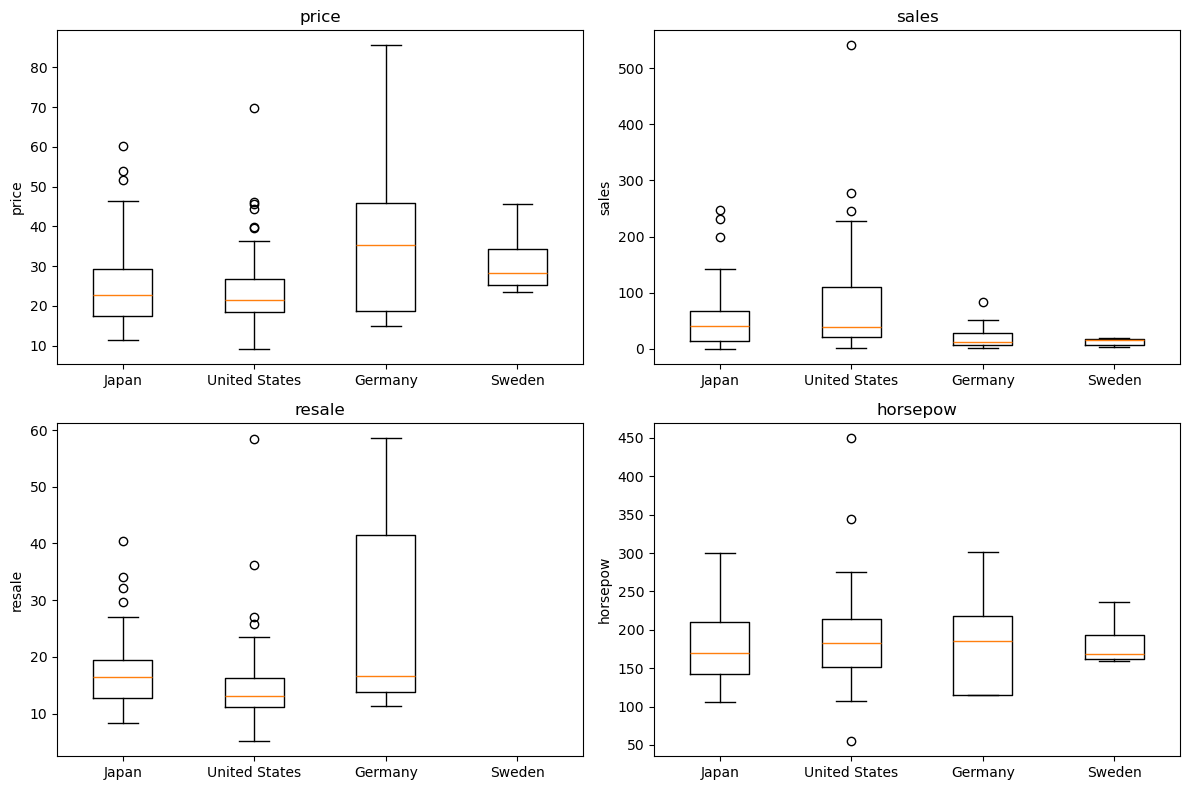

In [12]:
#Question 2

attributes = ['price', 'sales', 'resale', 'horsepow']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, attr in zip(axes, attributes):
  data_by_country = [df[df['country'] == c][attr].dropna() for c in countries]

  ax.boxplot(data_by_country, labels=countries)
  ax.set_title(attr)
  ax.set_ylabel(attr)
plt.tight_layout()
plt.show()

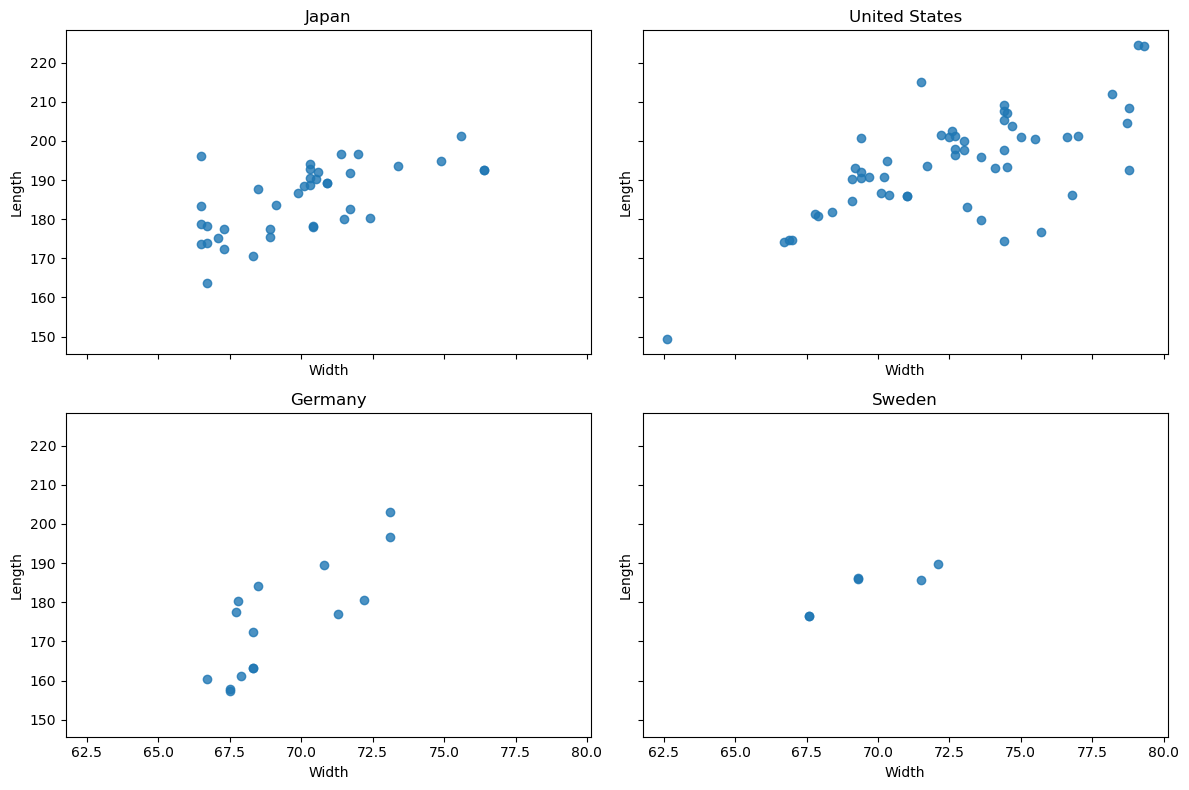

In [13]:
#Question 3

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
axes = axes.flatten()

for ax, country in zip(axes, countries):
  subset = df[df['country'] == country]
  ax.scatter(subset['width'], subset['length'], alpha=0.8)
  ax.set_title(country)
  ax.set_xlabel('Width')
  ax.set_ylabel('Length')

plt.tight_layout()
plt.show()

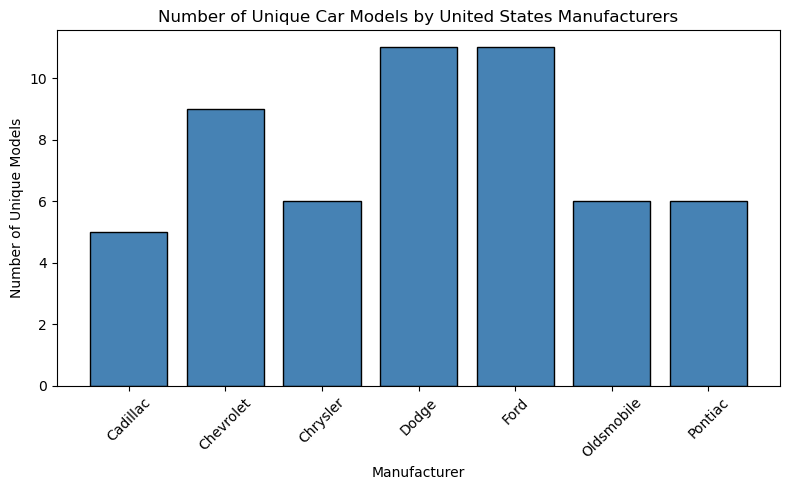

In [14]:
#Question 4

us_df = df[df['country'] == 'United States']
model_counts = us_df.groupby('manufact')['model'].nunique()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(model_counts.index, model_counts.values, color='steelblue', edgecolor='black')

ax.set_title('Number of Unique Car Models by United States Manufacturers')
ax.set_xlabel('Manufacturer')
ax.set_ylabel('Number of Unique Models')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

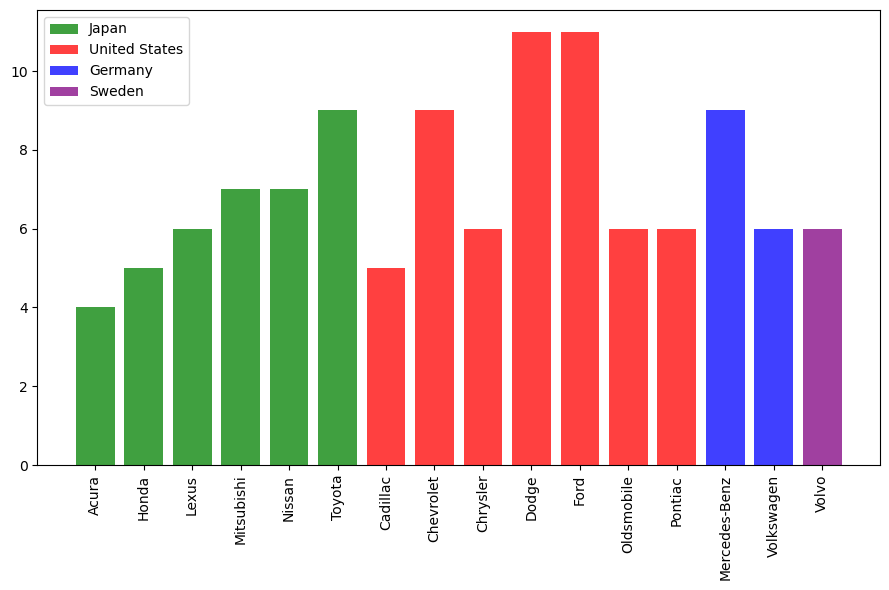

In [15]:
#Question 5

colors = ['green', 'red', 'blue', 'purple']
fig, ax = plt.subplots(figsize=(9, 6))

for country, color in zip(countries, colors):
  sub = df[df['country'] == country]
  counts = sub.groupby('manufact')['model'].nunique()
  ax.bar(counts.index, counts.values, color=color, alpha=0.75, label=country)

ax.legend(loc='upper left')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

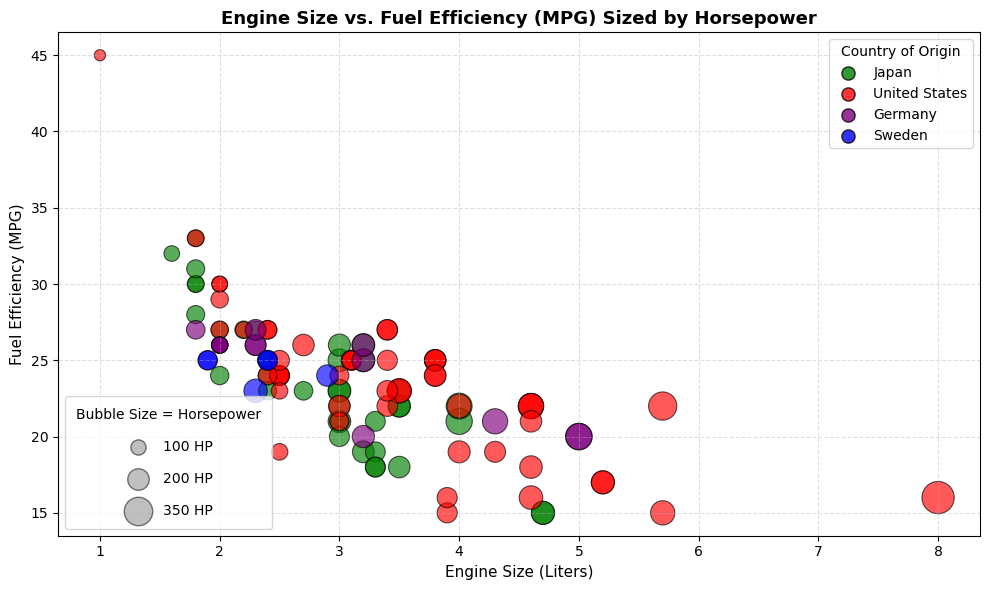

In [16]:
#Question 6

df_clean = df.dropna(subset=['engine_s', 'mpg', 'horsepow'])
countries = df_clean['country'].unique()
palette = {'Japan': 'Green','United States': 'Red','Germany': 'Purple','Sweden': 'Blue',}

fig, ax = plt.subplots(figsize=(10, 6))
country_handles = []

for country in countries:
  sub = df_clean[df_clean['country'] == country]
  ax.scatter(sub['engine_s'],sub['mpg'],s=sub['horsepow'] * 1.2,c=palette[country],alpha=0.65,edgecolors='black',linewidth=0.8,)
  h = ax.scatter([],[],s=90,c=palette[country],alpha=0.8,edgecolors='black',label=country,)
  country_handles.append(h)

ax.set_title('Engine Size vs. Fuel Efficiency (MPG) Sized by Horsepower',fontsize=13,fontweight='bold',)
ax.set_xlabel('Engine Size (Liters)', fontsize=11)
ax.set_ylabel('Fuel Efficiency (MPG)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.4)

leg1 = ax.legend(handles=country_handles,title='Country of Origin',loc='upper right',frameon=True,)

size_handles = [ax.scatter([],[],s=hp * 1.2,c='gray',alpha=0.5,edgecolors='black',label=f'{hp} HP',)
    for hp in [100, 200, 350]]
ax.legend(handles=size_handles,title='Bubble Size = Horsepower',loc='lower left',frameon=True,labelspacing=1.3,borderpad=0.8,)
ax.add_artist(leg1)

plt.tight_layout()
plt.show()